<a href="https://colab.research.google.com/github/YIJINGNIE/Transcript-Analysis/blob/main/Transcript%20Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape: (23, 10)
Dtypes:
 Year              int64
Season           object
Course_code      object
Course_number     int64
Description      object
Attempted         int64
Earned            int64
Grade            object
Points            int64
Repeated         object
dtype: object


,Year,Season,Course_code,Course_number,Description,Attempted,Earned,Grade,Points,Repeated
0,2024,Fall,ESOL,87,English pronunciation,2,2,S,0,NaN
1,2024,Fall,ESOL,88,International Student Life,2,2,S,0,NaN
2,2024,Fall,ESOL,113,Acad ESOL comp/read I,6,6,S,0,NaN
3,2024,Fall,PE,102,Strength Training,2,2,A,8,NaN
4,2025,Winter,BUS,101,Intro to Business,5,5,A,20,NaN


Cumulative GPA: 3.946


/tmp/ipykernel_1157/3553325750.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  term_gpa = gpa_courses.groupby(["Year", "season_num"]).apply(


Year  season_num
2024  4             4.000000
2025  1             3.666667
      2             4.000000
      3             4.000000
      4             4.000000
2026  1             4.000000
      2             4.000000
      3             4.000000
dtype: float64

,gpa_value
Course_code,
ACCT,4.0
ART,4.0
BIOL,4.0
BUS,4.0
CS,4.0
ECON,4.0
FILM,4.0
HUM,4.0
OCEA,4.0


,0
Course_code,
MATH,4
ESOL,3
ACCT,3
BUS,2
ENGL,2
ECON,2
CS,1
ART,1
BIOL,1


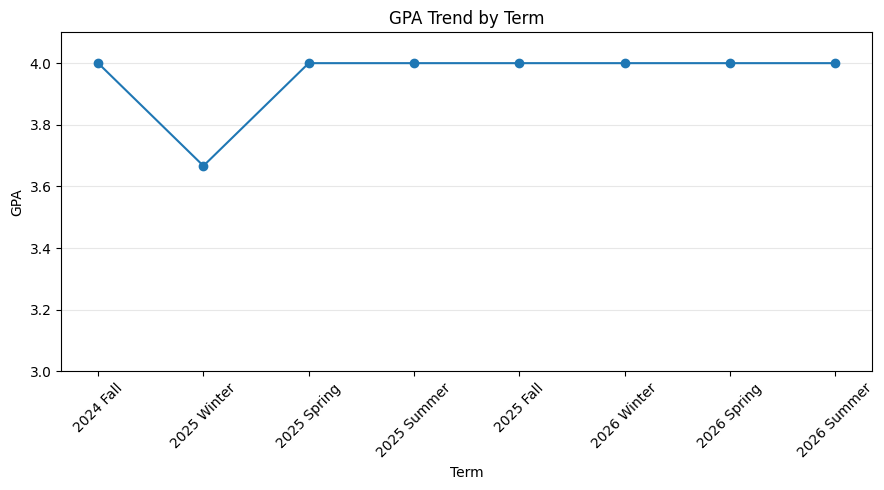

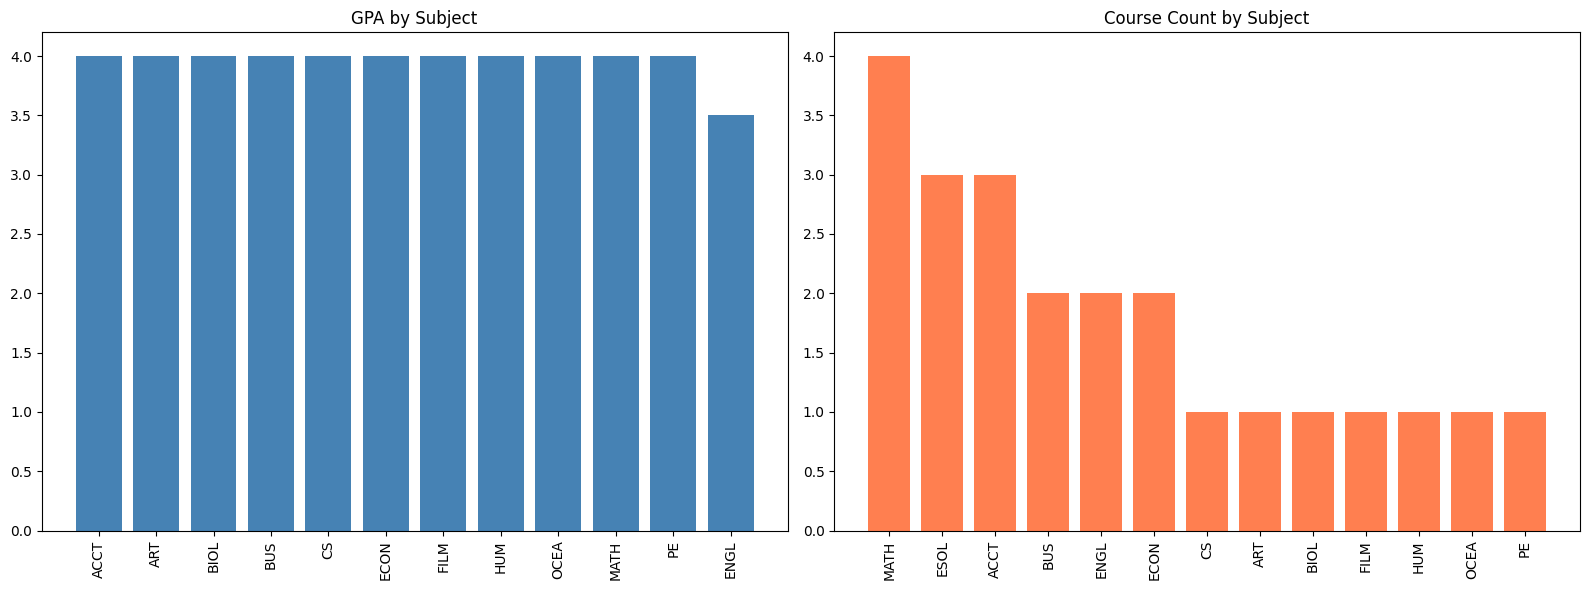

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load & inspect
df = pd.read_csv('/content/transcript.csv')
print("Shape:", df.shape)
print("Dtypes:\n", df.dtypes)
display(df.head())

# 2. Feature engineering
grade_map = {"A": 4.0, "B": 3.0, "C": 2.0, "D": 1.0, "F": 0.0}
df["gpa_value"] = df["Grade"].map(grade_map)

df["counts_toward_gpa"] = (df["Grade"] != "S") & (df["Repeated"] != "Excluded")

# season ordering so terms sort in real time order
season_order = {"Winter": 1, "Spring": 2, "Summer": 3, "Fall": 4}
df["season_num"] = df["Season"].map(season_order)

gpa_courses = df[df["counts_toward_gpa"]]

# 3. Cumulative GPA (credit-weighted)
cum_gpa = gpa_courses["Points"].sum() / gpa_courses["Attempted"].sum()
print("Cumulative GPA:", round(cum_gpa, 3))   # 3.946 — transcript shows 3.95 (rounded to 2dp)

# 4. GPA by term (time-ordered)
term_gpa = gpa_courses.groupby(["Year", "season_num"]).apply(
    lambda g: g["Points"].sum() / g["Attempted"].sum()
)
display(term_gpa)

# 5. By subject
subject_gpa   = gpa_courses.groupby("Course_code")["gpa_value"].mean().sort_values(ascending=False)
subject_count = df.groupby("Course_code").size().sort_values(ascending=False)
display(subject_gpa)
display(subject_count)

# 6. Chart: GPA trend by term
# auto-generate labels from the data
season_name = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
term_labels = [f"{year} {season_name[s]}" for year, s in term_gpa.index]

plt.figure(figsize=(9, 5))
plt.plot(term_gpa.values, marker="o")
plt.xticks(range(len(term_gpa)), term_labels, rotation=45)
plt.title("GPA Trend by Term")
plt.xlabel("Term"); plt.ylabel("GPA")
plt.ylim(3.0, 4.1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Chart: by-subject dashboard
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(subject_gpa.index, subject_gpa.values, color="steelblue")
axes[0].set_title("GPA by Subject")
axes[0].tick_params(axis="x", rotation=90)
axes[1].bar(subject_count.index, subject_count.values, color="coral")
axes[1].set_title("Course Count by Subject")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()